In [1]:
from utils.pathway_expansion import pathway_expansion

target_molecule: str = '[NH3+]CCCC[NH3+]' # 'NC(=O)NCCCC[NH3+]' #
commercial_molecules = [
	'NC(=[NH2+])NCCC[C@H]([NH3+])C(=O)[O-]', 
	]

pathway_expansion(target_smile=target_molecule,
                  building_blocks=commercial_molecules)

'./pathwayExpansion.json'

In [3]:
from utils.single_retro_fn import single_fn
from utils.chem import show_mol_svg
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import SVG

single_type = ['biocyc', 'ecreact']
target_molecule: str = 'O=CCCC(=O)O', #'C1=CC(=C(C=C1C(=O)O)O)O'
commercial_molecules = [
	#'C1=CC(=CC=C1C=CC(=O)O)O',
	#'CCOC1=C(C=CC(=C1)C=CC(=O)O)O',
]

# SVG(show_mol_svg(target_molecule, height=300))

mols = [Chem.MolFromSmiles(smi) for smi in [target_molecule]+commercial_molecules]
Draw.MolsToGridImage(mols, molsPerRow=5)

res = single_fn(target_molecule, commercial_molecules, ec_level=1)
print(res)

mols = [Chem.MolFromSmiles(r.reactants[0]) for r in res]
legends = [f"EC:{r.ec}-Smi:{r.similarity}" for r in res]
Draw.MolsToGridImage(mols, legends=legends, molsPerRow=5)

TypeError: No registered converter was able to produce a C++ rvalue of type std::__cxx11::basic_string<wchar_t, std::char_traits<wchar_t>, std::allocator<wchar_t> > from this Python object of type tuple

In [29]:
import graphviz  

p = graphviz.Graph(name='parent')

p.edge('spam', 'eggs')

c = graphviz.Graph(name='child', node_attr={'shape': 'box'})

c.edge('foo', 'bar')

p.subgraph(c)


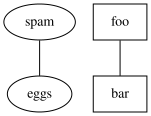

In [30]:
p

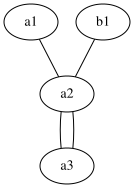

In [31]:
a = graphviz.Graph(name='p1')
a.edge('a1', 'a2')
a.edge('a2', 'a3')

b = graphviz.Graph(name='p2')
a.edge('b1', 'a2')
a.edge('a2', 'a3')

a.subgraph(b)

a

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from mpl_toolkits.mplot3d import Axes3D
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting
from typing import List, Optional

In [2]:
solutions = [
        [
            0.2,
            0.12940000000000002,
            0.1
        ],
        [
            0.3333333333333333,
            0.09566666666666668,
            0.1
        ],
        [
            0.3333333333333333,
            0.09566666666666668,
            0.1
        ],
        [
            0.5,
            0.1675,
            0.1
        ],
        [
            0.5,
            0.1675,
            0.1
        ],
        [
            0.25,
            0.20550000000000002,
            0.1
        ],
        [
            0.25,
            0.20550000000000002,
            0.1
        ],
        [
            0.3333333333333333,
            0.2066666666666667,
            0.118
        ],
        [
            0.3333333333333333,
            0.2066666666666667,
            0.118
        ],
        [
            0.2,
            0.1304,
            0.1
        ],
        [
            0.2,
            0.23020000000000002,
            0.1
        ],
        [
            0.25,
            0.1865,
            0.1
        ],
        [
            0.25,
            0.1865,
            0.1
        ],
        [
            0.2,
            0.1758,
            0.1
        ],
        [
            0.25,
            0.125,
            0.1
        ],
        [
            0.25,
            0.125,
            0.1
        ],
        [
            0.2,
            0.08099999999999999,
            0.1
        ],
        [
            0.25,
            0.13374999999999998,
            0.1
        ],
        [
            0.25,
            0.13374999999999998,
            0.1
        ],
        [
            0.25,
            0.15400000000000003,
            0.1
        ],
        [
            0.25,
            0.15400000000000003,
            0.1
        ],
        [
            0.2,
            0.11779999999999999,
            0.1
        ],
        [
            0.25,
            0.11624999999999999,
            0.1
        ],
        [
            0.25,
            0.0805,
            0.1
        ],
        [
            0.25,
            0.11624999999999999,
            0.1
        ],
        [
            0.2,
            0.10699999999999998,
            0.1
        ],
        [
            0.2,
            0.10699999999999998,
            0.1
        ],
        [
            0.2,
            0.2734,
            0.1
        ],
        [
            0.25,
            0.22949999999999998,
            0.1
        ],
        [
            0.25,
            0.22949999999999998,
            0.1
        ],
        [
            0.3333333333333333,
            0.34900000000000003,
            0.1
        ],
        [
            0.3333333333333333,
            0.34900000000000003,
            0.1
        ],
        [
            0.25,
            0.19624999999999998,
            0.118
        ],
        [
            0.25,
            0.19624999999999998,
            0.118
        ],
        [
            0.14285714285714285,
            0.13399999999999998,
            0.1
        ],
        [
            0.14285714285714285,
            0.13399999999999998,
            0.1
        ],
        [
            0.5,
            0.1675,
            0.1
        ],
        [
            0.25,
            0.26875,
            0.1
        ],
        [
            0.25,
            0.26875,
            0.1
        ],
        [
            0.16666666666666666,
            0.17733333333333334,
            0.1
        ],
        [
            0.16666666666666666,
            0.17733333333333334,
            0.1
        ],
        [
            0.25,
            0.17025,
            0.1
        ],
        [
            0.25,
            0.17025,
            0.1
        ],
        [
            0.2,
            0.213,
            0.1
        ],
        [
            0.25,
            0.12275000000000001,
            0.1
        ],
        [
            0.25,
            0.12275000000000001,
            0.1
        ]
    ]

# import numpy as np
# import matplotlib.pyplot as plt
objectives = np.array(solutions)

# fig = plt.figure(figsize=(8, 6))
# ax = fig.add_subplot(111, projection='3d')
# ax.scatter(objectives[:, 0], objectives[:, 1], objectives[:, 2], c='blue', s=50)
# ax.set_xlabel('Objective 1')
# ax.set_ylabel('Objective 2')
# ax.set_zlabel('Objective 3')
# ax.set_title('Pareto Front')


In [3]:
nds = NonDominatedSorting()
fronts = nds.do(objectives, return_rank=False)
fronts

[array([16, 23, 34, 35]),
 array([25, 26,  1,  2, 39, 40]),
 array([21, 22, 24]),
 array([ 0, 44, 45]),
 array([ 9, 14, 15]),
 array([13, 17, 18]),
 array([43, 19, 20]),
 array([10,  3,  4, 36, 41, 42]),
 array([27, 11, 12]),
 array([ 5,  6, 32, 33]),
 array([28, 29,  7,  8]),
 array([37, 38]),
 array([30, 31])]

In [4]:
for front_idx, front_indices in enumerate(fronts):
    print(f"Front-{front_idx}")
    print(objectives[front_indices])

Front-0
[[0.2        0.081      0.1       ]
 [0.25       0.0805     0.1       ]
 [0.14285714 0.134      0.1       ]
 [0.14285714 0.134      0.1       ]]
Front-1
[[0.2        0.107      0.1       ]
 [0.2        0.107      0.1       ]
 [0.33333333 0.09566667 0.1       ]
 [0.33333333 0.09566667 0.1       ]
 [0.16666667 0.17733333 0.1       ]
 [0.16666667 0.17733333 0.1       ]]
Front-2
[[0.2     0.1178  0.1    ]
 [0.25    0.11625 0.1    ]
 [0.25    0.11625 0.1    ]]
Front-3
[[0.2     0.1294  0.1    ]
 [0.25    0.12275 0.1    ]
 [0.25    0.12275 0.1    ]]
Front-4
[[0.2    0.1304 0.1   ]
 [0.25   0.125  0.1   ]
 [0.25   0.125  0.1   ]]
Front-5
[[0.2     0.1758  0.1    ]
 [0.25    0.13375 0.1    ]
 [0.25    0.13375 0.1    ]]
Front-6
[[0.2   0.213 0.1  ]
 [0.25  0.154 0.1  ]
 [0.25  0.154 0.1  ]]
Front-7
[[0.2     0.2302  0.1    ]
 [0.5     0.1675  0.1    ]
 [0.5     0.1675  0.1    ]
 [0.5     0.1675  0.1    ]
 [0.25    0.17025 0.1    ]
 [0.25    0.17025 0.1    ]]
Front-8
[[0.2    0.2734 0.1 

In [41]:
for path_idx in front_indices:
    print(path_idx)

6
7
4
5


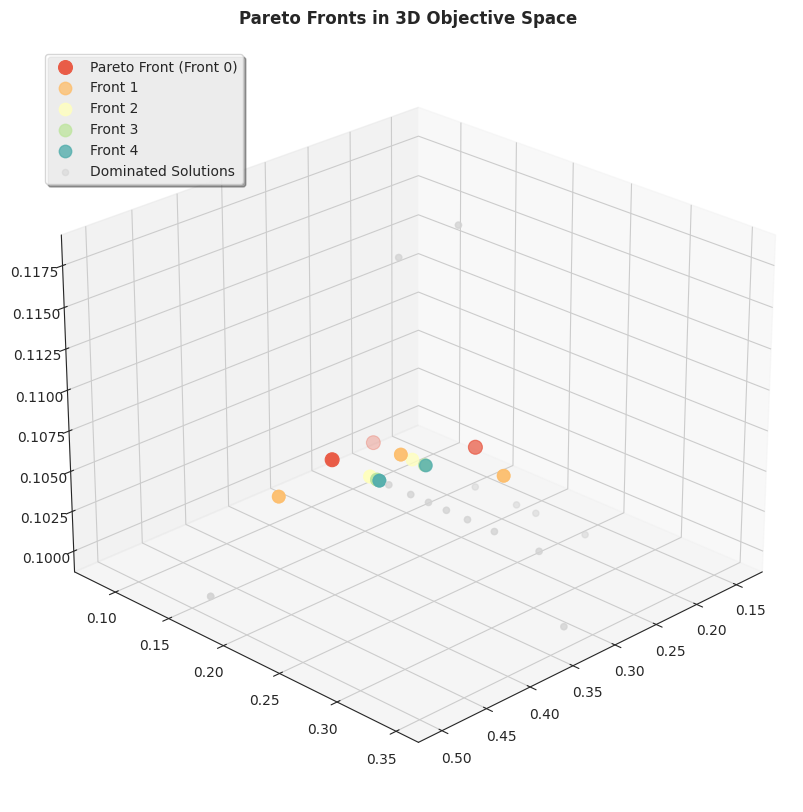

In [5]:
max_fronts_to_show = 5
axis_labels = [
        # "path_efficiency",        # 路径效率（质量/长度）
        "path_length_inv",
        "overall_retro_score",
        # "overall_similarity",     # 整体相似性
        "overall_feasibility",    # 整体可行性
        # "overall_yield"          # 整体产量
    ]
# --- 1. 数据准备和非支配排序 ---
nds = NonDominatedSorting()
fronts = nds.do(objectives, return_rank=False)

# --- 2. 绘图设置 (Seaborn风格) ---
# sns.set_theme(style="whitegrid", font="serif")
sns.set_style("white")
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# --- 3. 颜色和样式映射 ---
# 使用viridis色板，Front 0颜色最亮
palette = sns.color_palette("Spectral", n_colors=max_fronts_to_show)

# --- 4. 绘制每个Front的解 ---
for front_idx, front_indices in enumerate(fronts):
	front_objectives = objectives[front_indices]
	
	if front_idx == 0: # Pareto前沿 (Front 0)
		ax.scatter(
			front_objectives[:, 0], front_objectives[:, 1], front_objectives[:, 2],
			c=[palette[front_idx]],
			s=100,
			# edgecolor='black',
			linewidth=0.8,
			# depthshade=True,
			label=f"Pareto Front (Front 0)"
		)
	elif front_idx < max_fronts_to_show:
		ax.scatter(
			front_objectives[:, 0], front_objectives[:, 1], front_objectives[:, 2],
			c=[palette[front_idx]],
			s=80,
			# depthshade=True,
			alpha=0.8,
			label=f"Front {front_idx}"
		)
	else: # 合并其他Fronts
		if 'other_fronts' not in locals():
			other_fronts = front_objectives
		else:
			other_fronts = np.vstack([other_fronts, front_objectives])
# 绘制被支配的解
if 'other_fronts' in locals():
	ax.scatter(
		other_fronts[:, 0], other_fronts[:, 1], other_fronts[:, 2],
		c='lightgray',
		s=20,
		alpha=0.5,
		label=f"Dominated Solutions"
	)

# --- 6. 最终美化 ---
ax.set_title("Pareto Fronts in 3D Objective Space", fontsize=12, fontweight='bold')

# 创建图例
legend = ax.legend(loc='upper left', bbox_to_anchor=(0.02, 0.98), fontsize=10, frameon=True, fancybox=True, shadow=True)
legend.get_frame().set_alpha(0.8)

# 调整视角
ax.view_init(elev=25, azim=45)

In [26]:
max_fronts = 5
# 执行非支配排序
nds = NonDominatedSorting()
fronts = nds.do(objectives)

# 创建颜色映射
# colors = plt.cm.tab10(np.linspace(0, 1, min(max_fronts, len(fronts))))
from pypalettes import load_cmap
colors = load_cmap("Coconut")
color_map = {}

# 为每个Front分配颜色
for i, front in enumerate(fronts):
	if i < max_fronts:
		color_map[i] = colors[i]
	else:
		# 超过max_fronts的Front使用灰色
		color_map[i] = (0.7, 0.7, 0.7, 1.0)

# 特别设置Front 0为红色
if 0 in color_map:
	color_map[0] = (1.0, 0.0, 0.0, 1.0)  # 红色

fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# 绘制每个Front的解
legend_handles = []
for front_idx, front in enumerate(fronts):
	if front_idx >= max_fronts:
		# 只绘制前max_fronts个Front，其余的合并
		continue
		
	front_obj = objectives[front]
	color = color_map[front_idx]
	
	# 绘制当前Front的解
	scatter = ax.scatter(
		front_obj[:, 0], front_obj[:, 1], front_obj[:, 2],
		c=[color], s=50, alpha=0.8, 
		label=f"Front {front_idx}" if front_idx < max_fronts else "Other Fronts"
	)
	
	if front_idx < max_fronts:
		legend_handles.append(scatter)

# 绘制超出max_fronts的解（灰色）
other_indices = []
for front_idx in range(max_fronts, len(fronts)):
	other_indices.extend(fronts[front_idx])

if other_indices:
	other_obj = objectives[other_indices]
	scatter = ax.scatter(
		other_obj[:, 0], other_obj[:, 1], other_obj[:, 2],
		c=[(0.7, 0.7, 0.7, 0.6)], s=30, alpha=0.4,
		label="Other Fronts"
	)
	legend_handles.append(scatter)

# 设置坐标轴标签
ax.set_xlabel('Path Length (minimize)', fontsize=12)
ax.set_ylabel('Composite Retro Score (maximize)', fontsize=12)
ax.set_zlabel('Path Feasibility (maximize)', fontsize=12)
ax.set_title('3D Pareto Front with Multiple Fronts', fontsize=14)

# 添加图例
ax.legend(handles=legend_handles, loc='upper left', bbox_to_anchor=(0, 1))

# 添加网格
ax.grid(True, alpha=0.3)

# 调整视角以获得更好的视觉效果
ax.view_init(elev=20, azim=45)

TypeError: 'ListedColormap' object is not subscriptable

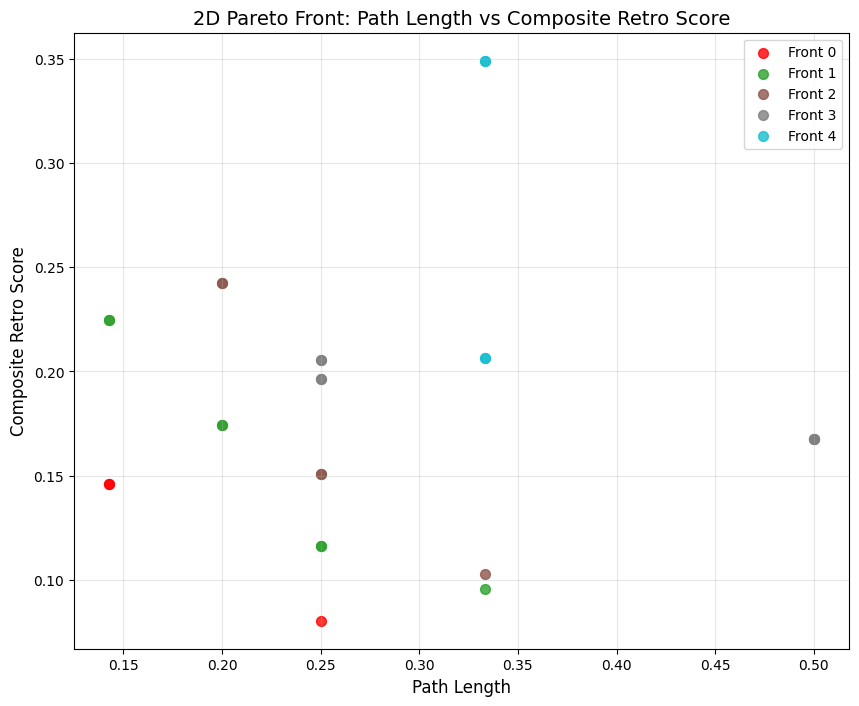

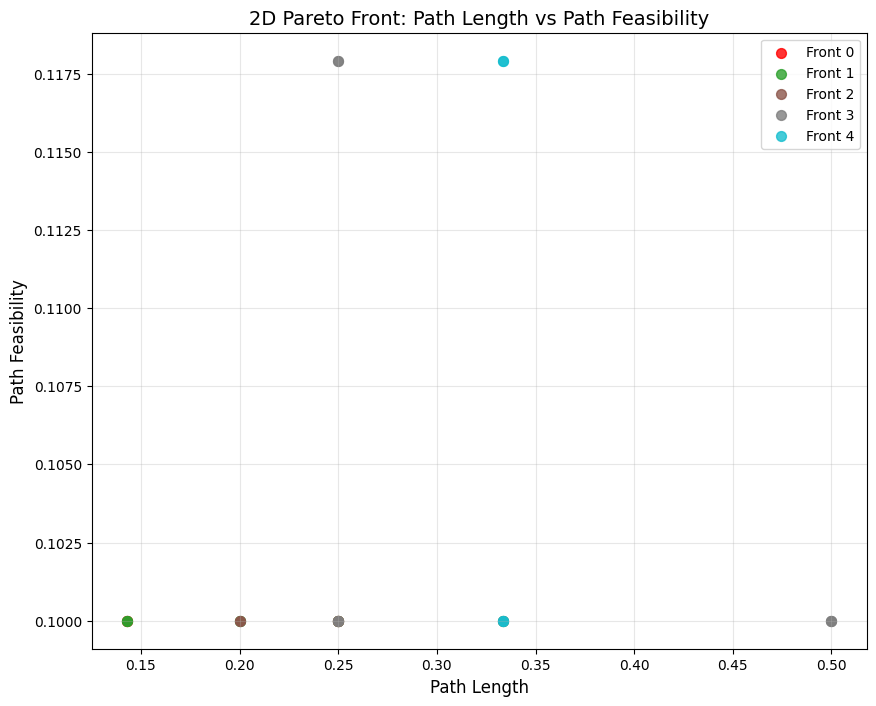

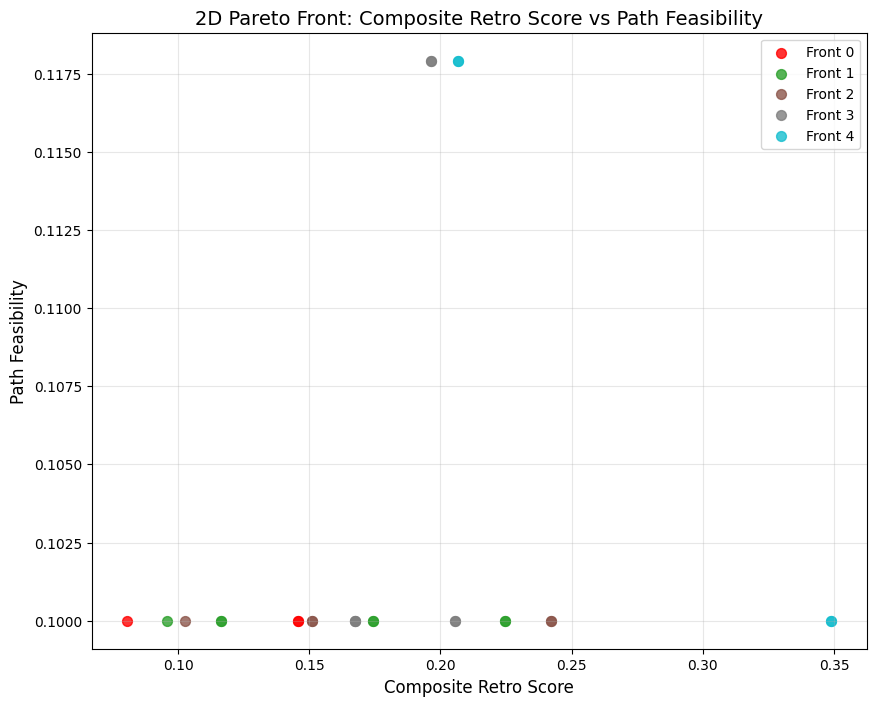

In [20]:
# 执行非支配排序
nds = NonDominatedSorting()
fronts = nds.do(objectives)

# 创建颜色映射
colors = plt.cm.tab10(np.linspace(0, 1, min(max_fronts, len(fronts))))
color_map = {}

for i, front in enumerate(fronts):
	if i < max_fronts:
		color_map[i] = colors[i]
	else:
		color_map[i] = (0.7, 0.7, 0.7, 1.0)

# 特别设置Front 0为红色
if 0 in color_map:
	color_map[0] = (1.0, 0.0, 0.0, 1.0)  # 红色

# 三个目标平面的组合
plane_combinations = [
	(0, 1, 'Path Length', 'Composite Retro Score'),
	(0, 2, 'Path Length', 'Path Feasibility'),
	(1, 2, 'Composite Retro Score', 'Path Feasibility')
]

saved_paths = []

for idx, (x_idx, y_idx, x_label, y_label) in enumerate(plane_combinations):
	fig, ax = plt.subplots(figsize=(10, 8))
	
	# 绘制每个Front的解
	legend_handles = []
	for front_idx, front in enumerate(fronts):
		if front_idx >= max_fronts:
			continue
			
		front_obj = objectives[front]
		color = color_map[front_idx]
		
		# 绘制当前Front的解
		scatter = ax.scatter(
			front_obj[:, x_idx], front_obj[:, y_idx],
			c=[color], s=50, alpha=0.8, 
			label=f"Front {front_idx}" if front_idx < max_fronts else "Other Fronts"
		)
		
		if front_idx < max_fronts:
			legend_handles.append(scatter)
	
	# 绘制超出max_fronts的解（灰色）
	other_indices = []
	for front_idx in range(max_fronts, len(fronts)):
		other_indices.extend(fronts[front_idx])
	
	if other_indices:
		other_obj = objectives[other_indices]
		scatter = ax.scatter(
			other_obj[:, x_idx], other_obj[:, y_idx],
			c=[(0.7, 0.7, 0.7, 0.6)], s=30, alpha=0.4,
			label="Other Fronts"
		)
		legend_handles.append(scatter)
	
	# 设置坐标轴标签
	ax.set_xlabel(x_label, fontsize=12)
	ax.set_ylabel(y_label, fontsize=12)
	ax.set_title(f'2D Pareto Front: {x_label} vs {y_label}', fontsize=14)
	
	# 添加图例
	ax.legend(handles=legend_handles, loc='best')
	
	# 添加网格
	ax.grid(True, alpha=0.3)

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.


findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

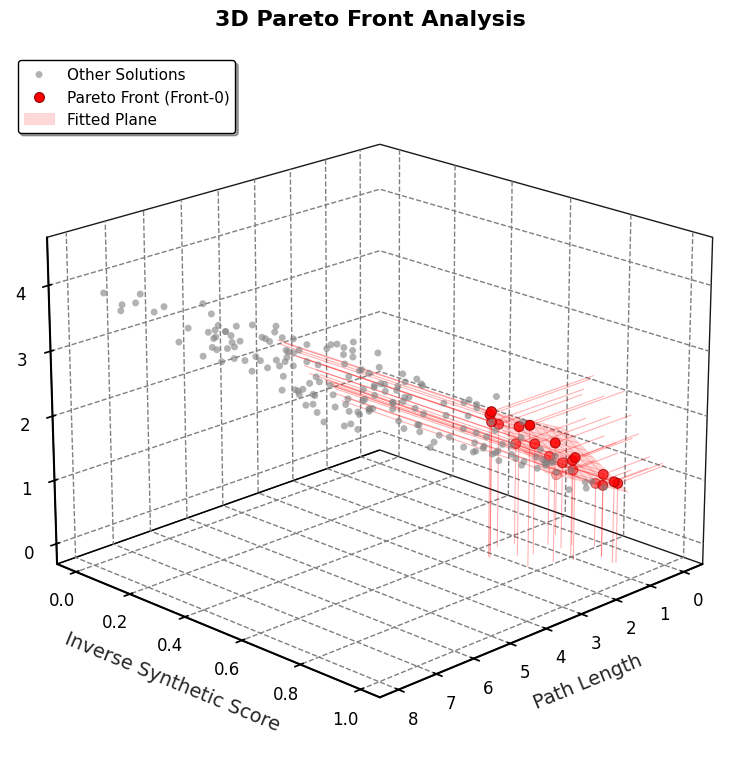

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.linalg import lstsq

# 设置OriginLab风格
# plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['axes.edgecolor'] = 'black'
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['ytick.color'] = 'black'
plt.rcParams['text.color'] = 'black'
plt.rcParams['grid.color'] = 'gray'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.3

# 生成示例数据（替换为您的实际数据）
np.random.seed(42)
n_points = 200

# 模拟Front-0（最优前沿）的点
front0_size = 20
path_length_f0 = np.random.uniform(1, 3, front0_size)
inverse_synthetic_score_f0 = np.random.uniform(0.7, 1.0, front0_size)
SA_score_f0 = 0.7 * path_length_f0 + 0.3 * inverse_synthetic_score_f0 + np.random.normal(0, 0.05, front0_size)

# 模拟其他Front的点
path_length_other = np.random.uniform(1, 8, n_points - front0_size)
inverse_synthetic_score_other = np.random.uniform(0, 1.0, n_points - front0_size)
SA_score_other = 0.5 * path_length_other + 0.5 * inverse_synthetic_score_other + np.random.normal(0, 0.1, n_points - front0_size)

# 合并数据
path_length = np.concatenate([path_length_f0, path_length_other])
inverse_synthetic_score = np.concatenate([inverse_synthetic_score_f0, inverse_synthetic_score_other])
SA_score = np.concatenate([SA_score_f0, SA_score_other])
fronts = np.concatenate([np.zeros(front0_size), np.ones(n_points - front0_size)])  # 0表示Front-0

# 创建图形
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# 设置背景颜色
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# 绘制所有点（灰色）
scatter_all = ax.scatter(
    path_length[fronts != 0], 
    inverse_synthetic_score[fronts != 0], 
    SA_score[fronts != 0],
    c='gray', alpha=0.6, s=25, edgecolors='none', label='Other Solutions'
)

# 绘制Front-0的点（红色）
scatter_front0 = ax.scatter(
    path_length[fronts == 0], 
    inverse_synthetic_score[fronts == 0], 
    SA_score[fronts == 0],
    c='red', s=50, edgecolors='darkred', linewidth=0.8, label='Pareto Front (Front-0)'
)

# 为Front-0的点添加投影线（红色）
for i in range(len(path_length)):
    if fronts[i] == 0:  # 只绘制Front-0的投影线
        # 投影到XY平面（路径长度 vs 逆合成分数）
        ax.plot([path_length[i], path_length[i]], 
                [inverse_synthetic_score[i], inverse_synthetic_score[i]], 
                [0, SA_score[i]], 
                color='red', alpha=0.3, linewidth=0.8)
        
        # 投影到XZ平面（路径长度 vs SAscore）
        ax.plot([path_length[i], path_length[i]], 
                [0, inverse_synthetic_score[i]], 
                [SA_score[i], SA_score[i]], 
                color='red', alpha=0.3, linewidth=0.8)
        
        # 投影到YZ平面（逆合成分数 vs SAscore）
        ax.plot([0, path_length[i]], 
                [inverse_synthetic_score[i], inverse_synthetic_score[i]], 
                [SA_score[i], SA_score[i]], 
                color='red', alpha=0.3, linewidth=0.8)

# 为Front-0拟合一个平面
if np.sum(fronts == 0) >= 3:
    # 获取Front-0的点
    x_f0 = path_length[fronts == 0]
    y_f0 = inverse_synthetic_score[fronts == 0]
    z_f0 = SA_score[fronts == 0]
    
    # 平面方程: z = a*x + b*y + c
    # 准备最小二乘法的矩阵: A = [x, y, 1], B = z
    A = np.c_[x_f0, y_f0, np.ones(x_f0.shape[0])]
    C, _, _, _ = lstsq(A, z_f0)
    
    # 创建网格
    x_range = np.linspace(min(x_f0), max(x_f0), 10)
    y_range = np.linspace(min(y_f0), max(y_f0), 10)
    X, Y = np.meshgrid(x_range, y_range)
    
    # 计算平面上的Z值
    Z = C[0]*X + C[1]*Y + C[2]
    
    # 绘制拟合平面
    surf = ax.plot_surface(X, Y, Z, color='red', alpha=0.15, 
                          label='Fitted Plane', shade=False, edgecolor='red', linewidth=0.5)

# 设置标签和标题
ax.set_xlabel('Path Length', fontsize=14, labelpad=10)
ax.set_ylabel('Inverse Synthetic Score', fontsize=14, labelpad=10)
ax.set_zlabel('SA Score', fontsize=14, labelpad=10)
ax.set_title('3D Pareto Front Analysis', fontsize=16, pad=20, weight='bold')

# 设置视角
ax.view_init(elev=20, azim=45)

# 添加网格
ax.grid(True, linestyle='--', alpha=0.3)

# 添加图例
legend = ax.legend(loc='upper left', bbox_to_anchor=(0, 1), frameon=True, fancybox=True, shadow=True)
legend.get_frame().set_facecolor('white')
legend.get_frame().set_edgecolor('black')
legend.get_frame().set_linewidth(1.0)

# 美化坐标轴
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
ax.xaxis.pane.set_edgecolor('black')
ax.yaxis.pane.set_edgecolor('black')
ax.zaxis.pane.set_edgecolor('black')
ax.xaxis.pane.set_alpha(0.9)
ax.yaxis.pane.set_alpha(0.9)
ax.zaxis.pane.set_alpha(0.9)

# 设置刻度
ax.tick_params(axis='both', which='major', labelsize=12)

# 调整布局
plt.tight_layout()

# 保存图像（可选）
# plt.savefig('3d_pareto_front.png', dpi=300, bbox_inches='tight')

plt.show()

In [1]:
from utils.utils import json2data
json_file = 'results/PWY-43_biocyc_20250820_115231/synthesis_tree_all_data.json'
data = json2data(json_file)
data

{'project': 'PWY-43',
 'target_molecule': '[NH3+]CCCC[NH3+]',
 'commercial_molecules': ['NC(=[NH2+])NCCC[C@H]([NH3+])C(=O)[O-]'],
 'global_solutions': [[0.3333333333333333, 0.10266666666666667, 0.1],
  [0.3333333333333333, 0.09566666666666668, 0.1],
  [0.5, 0.1675, 0.1],
  [0.5, 0.1675, 0.1],
  [0.3333333333333333, 0.2066666666666667, 0.1179093534633896],
  [0.3333333333333333, 0.2066666666666667, 0.1179093534633896],
  [0.3333333333333333, 0.34900000000000003, 0.1],
  [0.3333333333333333, 0.34900000000000003, 0.1],
  [0.5, 0.1675, 0.1],
  [0.25, 0.20550000000000002, 0.1],
  [0.25, 0.20550000000000002, 0.1],
  [0.25, 0.11624999999999999, 0.1],
  [0.25, 0.0805, 0.1],
  [0.25, 0.11624999999999999, 0.1],
  [0.25, 0.19624999999999998, 0.1179093534633896],
  [0.25, 0.19624999999999998, 0.1179093534633896],
  [0.14285714285714285, 0.2245714285714286, 0.1],
  [0.14285714285714285, 0.2245714285714286, 0.1],
  [0.2, 0.24219999999999997, 0.1],
  [0.2, 0.24219999999999997, 0.1],
  [0.142857142857

In [2]:
data['records']

[{'iteration': 1,
  'elapsed_time': 2.563220500946045,
  'tree_size': 37,
  'complete_paths': 0,
  'pareto_front_size': 0,
  'hypervolume': 0.0},
 {'iteration': 2,
  'elapsed_time': 3.805778741836548,
  'tree_size': 63,
  'complete_paths': 0,
  'pareto_front_size': 0,
  'hypervolume': 0.0},
 {'iteration': 3,
  'elapsed_time': 5.59022068977356,
  'tree_size': 93,
  'complete_paths': 1,
  'pareto_front_size': 1,
  'hypervolume': 0.0},
 {'iteration': 4,
  'elapsed_time': 7.175627708435059,
  'tree_size': 117,
  'complete_paths': 2,
  'pareto_front_size': 1,
  'hypervolume': 0.0},
 {'iteration': 5,
  'elapsed_time': 7.750343084335327,
  'tree_size': 131,
  'complete_paths': 2,
  'pareto_front_size': 1,
  'hypervolume': 0.0},
 {'iteration': 6,
  'elapsed_time': 9.176496982574463,
  'tree_size': 147,
  'complete_paths': 4,
  'pareto_front_size': 1,
  'hypervolume': 0.0},
 {'iteration': 7,
  'elapsed_time': 9.82042407989502,
  'tree_size': 159,
  'complete_paths': 4,
  'pareto_front_size': 1,

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

iteration_data = data['records']
df = pd.DataFrame(iteration_data)
df.head()

,iteration,elapsed_time,tree_size,complete_paths,pareto_front_size,hypervolume
0,1,2.563221,37,0,0,0.0
1,2,3.805779,63,0,0,0.0
2,3,5.590221,93,1,1,0.0
3,4,7.175628,117,2,1,0.0
4,5,7.750343,131,2,1,0.0


In [8]:
df.pareto_front_size.to_list()

[0,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 3,
 3,
 3,
 3,
 3,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3,
 3]

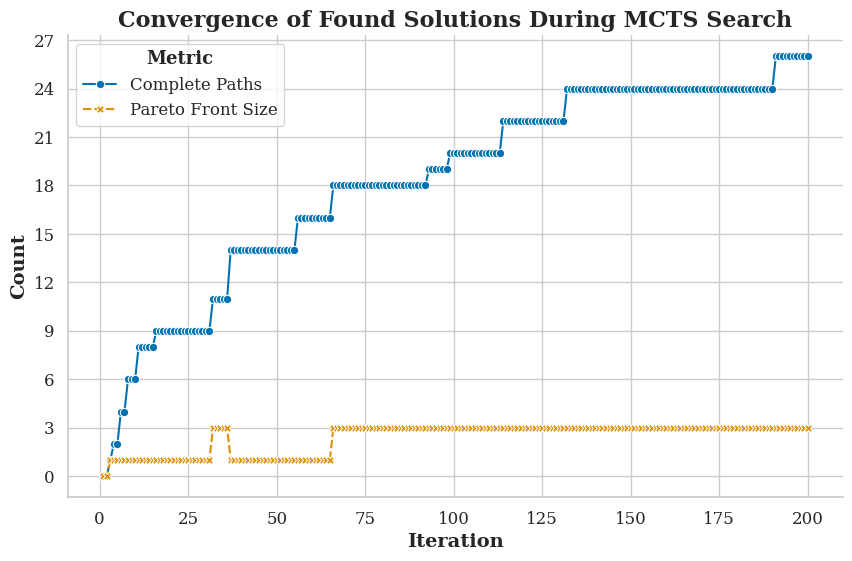

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# df = pd.DataFrame([vars(record) for record in iteration_data])

# 为了在一张图上优雅地展示两个指标，我们将数据从宽格式转换为长格式
df_long = df.melt(
	id_vars=['iteration'], 
	value_vars=['complete_paths', 'pareto_front_size'],
	var_name='Metric', 
	value_name='Count'
)

# 美化指标名称以在图例中显示
df_long['Metric'] = df_long['Metric'].map({
	'complete_paths': 'Complete Paths',
	'pareto_front_size': 'Pareto Front Size'
})

# --- 绘图设置 (科技论文风格) ---
sns.set_theme(style="whitegrid") # 设置seaborn主题，whitegrid非常适合论文
plt.rc('font', family='serif')   # 优先使用衬线字体

fig, ax = plt.subplots(figsize=(10, 6)) # 设置图像尺寸

# --- 使用seaborn绘制线图 ---
sns.lineplot(
	data=df_long,
	x='iteration',
	y='Count',
	hue='Metric',          # 根据'Metric'列区分颜色
	style='Metric',        # 根据'Metric'列区分线条样式 (实线/虚线)
	markers=True,          # 在每个数据点上添加标记
	# markersize=8,          # 标记大小
	# linewidth=2.5,         # 线条宽度
	palette='colorblind',  # 使用对色盲友好的调色板
	ax=ax
)

# --- 图形细节美化 ---
# 设置标题和坐标轴标签，并加粗
ax.set_title("Convergence of Found Solutions During MCTS Search", fontsize=16, fontweight='bold')
ax.set_xlabel("Iteration", fontsize=14, fontweight='bold')
ax.set_ylabel("Count", fontsize=14, fontweight='bold')

# 设置坐标轴刻度字体大小
ax.tick_params(axis='both', which='major', labelsize=12)

# 确保Y轴刻度为整数，因为我们是在计数
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

# 优化图例
legend = ax.legend(title="Metric", fontsize=12, title_fontsize=13)
legend.get_title().set_fontweight('bold')

# 移除顶部和右侧的边框线，使图形更简洁
sns.despine(ax=ax)

# # 调整布局以防止标签被裁剪
# plt.tight_layout()

# # --- 保存图像 ---
# if save_path:
# 	# 保存为高分辨率图像，dpi=300是印刷标准
# 	plt.savefig(save_path, dpi=300, bbox_inches='tight')
# 	print(f"Convergence curve saved to: {save_path}")

# # 关闭图形以释放内存
# plt.close()

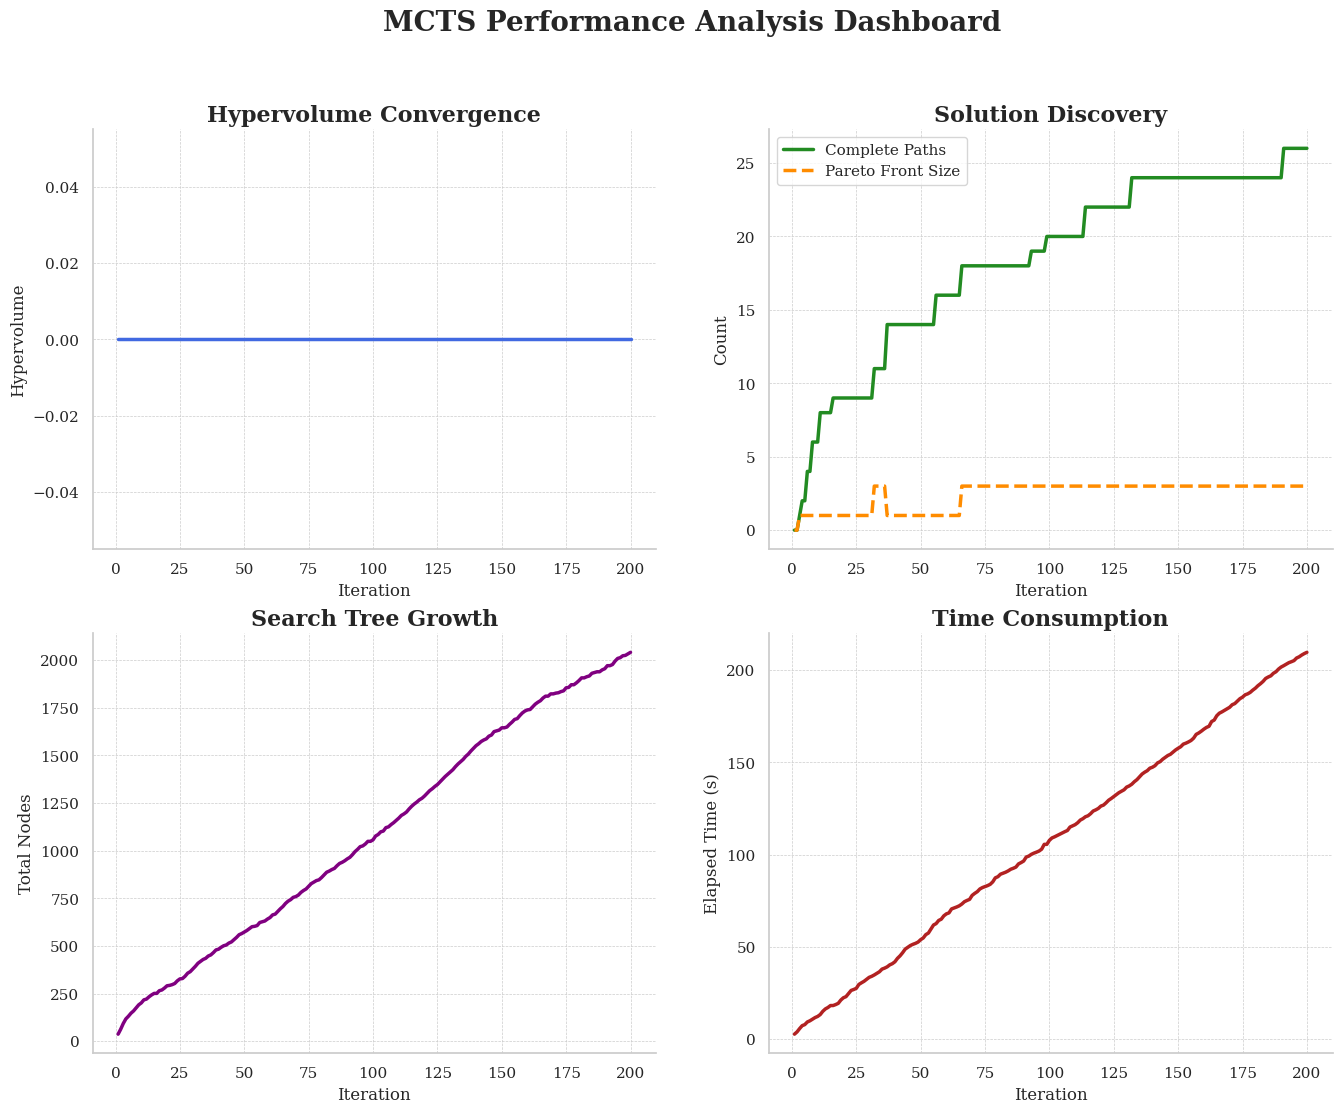

In [10]:
# --- 绘图设置 ---
sns.set_theme(style="whitegrid", font="serif")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("MCTS Performance Analysis Dashboard", fontsize=20, fontweight='bold')

# --- 1. 超体积收敛性 (Hypervolume Convergence) ---
sns.lineplot(data=df, x='iteration', y='hypervolume', ax=axes[0, 0], color='royalblue', linewidth=2.5)
axes[0, 0].set_title("Hypervolume Convergence", fontsize=16, fontweight='bold')
axes[0, 0].set_xlabel("Iteration", fontsize=12)
axes[0, 0].set_ylabel("Hypervolume", fontsize=12)

# --- 2. 解的发现 (Solution Discovery) ---
sns.lineplot(data=df, x='iteration', y='complete_paths', ax=axes[0, 1], 
				label='Complete Paths', color='forestgreen', linewidth=2.5, linestyle='-')
sns.lineplot(data=df, x='iteration', y='pareto_front_size', ax=axes[0, 1], 
				label='Pareto Front Size', color='darkorange', linewidth=2.5, linestyle='--')
axes[0, 1].set_title("Solution Discovery", fontsize=16, fontweight='bold')
axes[0, 1].set_xlabel("Iteration", fontsize=12)
axes[0, 1].set_ylabel("Count", fontsize=12)
axes[0, 1].legend(fontsize=11)

# --- 3. 搜索树增长 (Search Tree Growth) ---
sns.lineplot(data=df, x='iteration', y='tree_size', ax=axes[1, 0], color='purple', linewidth=2.5)
axes[1, 0].set_title("Search Tree Growth", fontsize=16, fontweight='bold')
axes[1, 0].set_xlabel("Iteration", fontsize=12)
axes[1, 0].set_ylabel("Total Nodes", fontsize=12)

# --- 4. 时间消耗 (Time Consumption) ---
sns.lineplot(data=df, x='iteration', y='elapsed_time', ax=axes[1, 1], color='firebrick', linewidth=2.5)
axes[1, 1].set_title("Time Consumption", fontsize=16, fontweight='bold')
axes[1, 1].set_xlabel("Iteration", fontsize=12)
axes[1, 1].set_ylabel("Elapsed Time (s)", fontsize=12)

# --- 全局美化 ---
for ax in axes.flat:
	ax.grid(True, which='both', linestyle='--', linewidth=0.5)
	ax.tick_params(axis='both', which='major', labelsize=11)
	sns.despine(ax=ax)

# plt.tight_layout(rect=[0, 0, 1, 0.96]) # 调整布局以适应主标题

# # --- 保存 ---
# if save_path:
# 	plt.savefig(save_path, dpi=300)
# 	print(f"Performance dashboard saved to: {save_path}")
# plt.close()

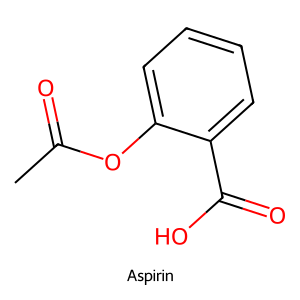

In [5]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole  # 用于在 Jupyter 中显示图像
IPythonConsole.ipython_useSVG = True  # 使用 SVG 格式以获得更高质量的图像

# 1. 准备分子（以 SMILES 字符串为例）
smiles = "CC(=O)OC1=CC=CC=C1C(=O)O"  # 阿司匹林的 SMILES
mol = Chem.MolFromSmiles(smiles)

# 2. 绘制单个分子图并添加图例
img = Draw.MolToImage(mol, size=(300, 300), legend="Aspirin")  # 设置图例为 "Aspirin"

# 3. 显示图像（在 Jupyter 环境中）
img.show()

# 4. 可选：保存图像到文件
img.save("aspirin_with_legend.png")

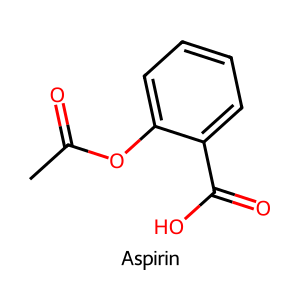

In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
from PIL import Image

# 1. 创建一个分子对象
mol = Chem.MolFromSmiles('O=C(C)Oc1ccccc1C(=O)O') # 阿司匹林

# 2. 定义图例
legend = 'Aspirin'

# 3. 创建并设置 MolDrawOptions (与方法一完全相同)
options = Draw.MolDrawOptions()
options.legendFontSize = 20
options.bondLineWidth = 3
options.padding = 0.1
options.setAtomPalette({6: (0, 0, 0), 8: (1, 0, 0)})

# 4. 调用 MolToImage 函数绘制图像
# 注意：直接传入分子对象和图例字符串，参数名为 options
img = Draw.MolToImage(mol, legend=legend, size=(300, 300), options=options)

# 5. 显示图像
img

In [10]:
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
import os

# 1. 创建分子对象
smiles = 'O=C(C)Oc1ccccc1C(=O)O'
mol = Chem.MolFromSmiles(smiles)

# 准备分子用于绘制（这是一个好习惯）
rdMolDraw2D.PrepareMolForDrawing(mol)

# 2. 创建一个 MolDraw2DSVG 绘图对象
# 参数是图像的宽度和高度（单位：像素）
drawer = rdMolDraw2D.MolDraw2DSVG(400, 300)

# 3. (可选) 设置绘图选项
options = drawer.drawOptions()
options.clearBackground = False
options.legendFontSize = 20
options.legendFraction = 0.2  # 分配给图例区域的高度比例
options.setAtomPalette({6: (0, 0, 0), 8: (1, 0, 0)}) # 将碳设为黑色，氧设为红色
options.bondLineWidth = 2

# 4. 定义图例
legend = "Aspirin\n(Acetylsalicylic acid)"

# 5. 绘制分子，并传入图例
drawer.DrawMolecule(mol, legend=legend)

# 6. 完成绘制过程
drawer.FinishDrawing()

# 7. 获取 SVG 格式的文本内容
svg_content = drawer.GetDrawingText()

# 8. 将 SVG 内容写入文件
file_path = 'molecule_with_legend.svg'
with open(file_path, 'w') as f:
    f.write(svg_content)

print(f"分子图像已成功保存到: {os.path.abspath(file_path)}")

分子图像已成功保存到: /root/autodl-tmp/caoyh/MooRetro-master/molecule_with_legend.svg


In [9]:
from utils.chem import show_mol_svg
show_mol_svg(smiles, legend='test', save_file_name='test.svg')

In [ ]:
os.listdir

In [1]:
from utils.single_retro_fn import single_fn

single_type = ['biocyc', 'ecreact']
target_molecule: str = 'CCCC=O'
commercial_molecules = [ 
	# 'CCCC=O',
    'CCCC(=O)SCCNC(=O)CCNC(=O)[C@H](O)C(C)(C)COP(=O)([O-])OP(=O)([O-])OC[C@H]1O[C@@H](n2cnc3c(N)ncnc32)[C@H](O)[C@@H]1OP(=O)([O-])[O-]',
	'CC(=O)CC(=O)SCCNC(=O)CCNC(=O)[C@H](O)C(C)(C)COP(=O)([O-])OP(=O)([O-])OC[C@H]1O[C@@H](n2cnc3c(N)ncnc32)[C@H](O)[C@@H]1OP(=O)([O-])[O-]', 
	'CC(=O)SCCNC(=O)CCNC(=O)[C@H](O)C(C)(C)COP(=O)([O-])OP(=O)([O-])OC[C@H]1O[C@@H](n2cnc3c(N)ncnc32)[C@H](O)[C@@H]1OP(=O)([O-])[O-]',
	'C[C@H](O)CC(=O)SCCNC(=O)CCNC(=O)[C@H](O)C(C)(C)COP(=O)([O-])OP(=O)([O-])OC[C@H]1O[C@@H](n2cnc3c(N)ncnc32)[C@H](O)[C@@H]1OP(=O)([O-])[O-]',
	]


res = single_fn(target_molecule, commercial_molecules, ec_level=3)
res

[SingleStepResult(reactants=['CCCC(=O)C(=O)O'], scores=0.17, ec='4.1.1', templates='[Attaching][Group]*C(=O)O:3[EC]4.1.1', confidence=0.0, reaction_type='', similarity=0.206, yield_estimate=0.7703136099586216, top_k='Top-1'),
 SingleStepResult(reactants=['CC=CC=O'], scores=0.141, ec='1.3.1', templates='[Change][Bond]C=C:2.1[EC]1.3.1', confidence=0.0, reaction_type='', similarity=0.25, yield_estimate=0.14941850882327556, top_k='Top-3'),
 SingleStepResult(reactants=['CCCC(=O)SCCNC(=O)CCNC(=O)C(O)C(C)(C)COP(=O)(O)OP(=O)(O)OCC1OC(n2cnc3c(N)ncnc32)C(O)C1OP(=O)(O)O'], scores=0.105, ec='1.2.1', templates='[Attaching][Group]*SCCNC(=O)CCNC(=O)C(O)C(C)(C)COP(=O)(O)OP(=O)(O)OCC1OC(n2cnc3c(N)ncnc32)C(O)C1OP(=O)(O)O:3[EC]1.2.1', confidence=0.0, reaction_type='', similarity=1.0, yield_estimate=0.834220966060378, top_k='Top-4'),
 SingleStepResult(reactants=['CCCC[N+](=O)[O-]'], scores=0.094, ec='1.13.12', templates='[Delete][Bond]C=O:3.4[Leaving][Group]*=O:4[Attaching][Group]*[N+](=O)[O-]:3[EC]1.13.1

CCCC(=O)SCCNC(=O)CCNC(=O)C(O)C(C)(C)COP(=O)(O)OP(=O)(O)OCC1OC(n2cnc3c(N)ncnc32)C(O)C1OP(=O)(O)O


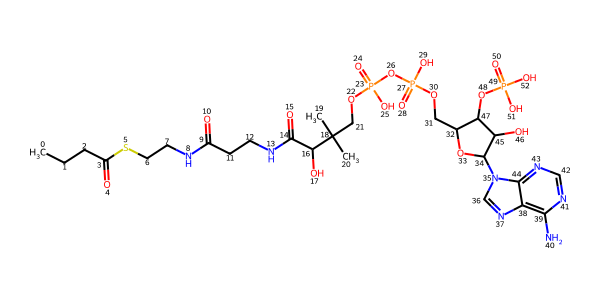

In [11]:
smi = res[2].reactants[0]
print(smi)
from utils.chem import show_mol_svg
from rdkit import Chem
from IPython.display import SVG

SVG(show_mol_svg(smi, height=600))

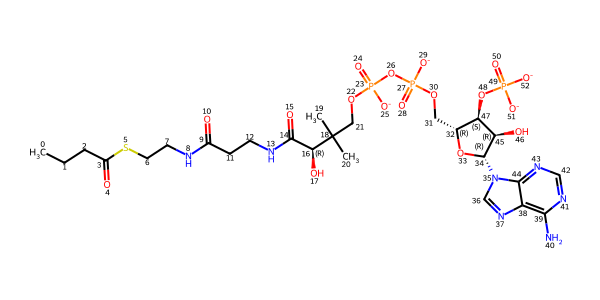

In [12]:
SVG(show_mol_svg(commercial_molecules[0], height=600))

[1.0]

In [1]:
target_molecule: str = '[NH3+]CCCC[NH3+]'
commercial_molecules = [
    'NC(=O)NCCCC[NH3+]'
    # 'NC(=[NH2+])NCCC[C@H]([NH3+])C(=O)[O-]'
	]

from enzretro.model.product2order import Product2orderEC, BioCyc
import torch
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
p2oe = BioCyc(ec_num=3, device=device)
result = p2oe(target_molecule)
result[1]


['[Attaching][Group]*C(=O)[O-]:1[EC]4.1.1',
 '[Attaching][Group]*C(=O)O:1[EC]4.1.1',
 '[Delete][Bond]CN:1.0[Add][Bond]C=N:0.1[Leaving][Group]*[NH3+]:0[EC]2.6.1',
 '[Attaching][Group]*C(N)=O:0[EC]3.5.1',
 '[Delete][Bond]CN:1.0[Leaving][Group]*[NH3+]:0[Attaching][Group]*=O:1[EC]2.6.1',
 '[Delete][Bond]CN:4.5[Leaving][Group]*[NH3+]:5[Attaching][Group]*=O:4[EC]2.6.1',
 '[Delete][Bond]CN:1.0[Add][Bond]CN:7.8[Leaving][Group]*[NH3+]:0[Attaching][Group]*=O:1[EC]2.6.1',
 '[Delete][Bond]CN:1.0[Add][Bond]CN:3.4[Leaving][Group]*[NH3+]:0[Attaching][Group]*=O:1[EC]2.6.1',
 '[Attaching][Group]*C(=N)N:0[EC]3.5.3',
 '[Delete][Bond]CN:1.0[Add][Bond]CN:7.8[Leaving][Group]*[NH3+]:0[EC]2.6.1']

In [14]:
from utils.single_retro_fn import single_fn
target_molecule = 'N=C(N)NCCCCN'
commercial_molecules = ['NC(=[NH2+])NCCC[C@H]([NH3+])C(=O)[O-]']
res = single_fn(target_molecule, commercial_molecules, ec_level=3)
res 

[SingleStepResult(reactants=['N=C(N)NCCCC(N)C(=O)O'], scores=0.498, ec='4.1.1', templates='[Attaching][Group]*C(=O)O:7[EC]4.1.1', confidence=0.0, reaction_type='', similarity=1.0, yield_estimate=0.883, top_k='Top-1'),
 SingleStepResult(reactants=['CC(=O)NC(=N)NCCCCN'], scores=0.064, ec='3.5.1', templates='[Attaching][Group]*C(C)=O:2[EC]3.5.1', confidence=0.0, reaction_type='', similarity=0.525, yield_estimate=0.324, top_k='Top-3'),
 SingleStepResult(reactants=['NC(N)=NCCCC(N)C(=O)O'], scores=0.04, ec='4.1.1', templates='[Change][Bond]C=N:3.1[Change][Bond]CN:1.0[Attaching][Group]*C(=O)O:7[EC]4.1.1', confidence=0.0, reaction_type='', similarity=0.556, yield_estimate=0.875, top_k='Top-4'),
 SingleStepResult(reactants=['N=C(NCCCCN)NC(N)=O'], scores=0.034, ec='3.5.1', templates='[Attaching][Group]*C(N)=O:2[EC]3.5.1', confidence=0.0, reaction_type='', similarity=0.488, yield_estimate=0.584, top_k='Top-6'),
 SingleStepResult(reactants=['NCCCCN'], scores=0.02, ec='2.1.3', templates='[Delete][B

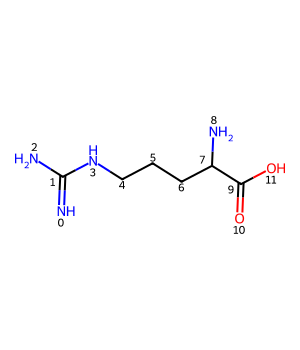

In [15]:
smi = 'N=C(N)NCCCC(N)C(=O)O'
from utils.chem import show_mol_svg
from rdkit import Chem
from IPython.display import SVG

SVG(show_mol_svg(smi))

In [21]:
res = single_fn(target_molecule, commercial_molecules, ec_level=3, single_fn_type='ecreact')
res 

[SingleStepResult(reactants=['[NH3+]CCCC([NH3+])C(=O)O'], scores=0.219, ec='4.1.1', templates='[Attaching][Group]*C(=O)O:1[Attaching][Group][H+]:-1[EC]4.1.1', confidence=0.0, reaction_type='', similarity=0.178, yield_estimate=0.8214174662282915, top_k='Top-1'),
 SingleStepResult(reactants=['[NH3+]CCC[C@@H]([NH3+])C(=O)O'], scores=0.1, ec='4.1.1', templates='[Attaching][Group]*C(=O)O:1[Attaching][Group][H+]:-1[Change][Atom]C@@:1[EC]4.1.1', confidence=0.0, reaction_type='', similarity=0.178, yield_estimate=0.11273969459156441, top_k='Top-3'),
 SingleStepResult(reactants=['CCCC[NH3+]'], scores=0.091, ec='2.1.1', templates='[Delete][Bond]CN:0.1[Attaching][Group]*[S+](C)CC1OC(n2cnc3c(N)ncnc32)C(O)C1O:0[EC]2.1.1', confidence=0.0, reaction_type='', similarity=0.875, yield_estimate=0.40698795759556095, top_k='Top-4'),
 SingleStepResult(reactants=['[NH3+]CCC[C@H]([NH3+])C(=O)O'], scores=0.064, ec='4.1.1', templates='[Attaching][Group]*C(=O)O:1[Attaching][Group][H+]:-1[Change][Atom]C@:1[EC]4.1.1

In [9]:
from rdkit import Chem

# 原始错误的 SMILES
smi = "NC(=O)[NH3+]CCCC[NH3+]"

mol = Chem.MolFromSmiles(smi, sanitize=False)  # 不进行检查，先读进来
editable = Chem.RWMol(mol)

# 找到带 +1 电荷的氮原子
for atom in editable.GetAtoms():
    if atom.GetSymbol() == "N" and atom.GetFormalCharge() == 1:
        # 判断是不是中间的氮（连接到碳，不是末端 [NH3+]）
        if any(nbr.GetSymbol() == "C" for nbr in atom.GetNeighbors()):
            atom.SetFormalCharge(0)       # 去掉正电荷
            atom.SetNumExplicitHs(1)      # 给一个氢，保持 N-H
            break

# 转换回分子对象并 sanitize
mol2 = editable.GetMol()
Chem.SanitizeMol(mol2)

# 输出修正后的 SMILES
print(Chem.MolToSmiles(mol2))


NC(=O)NCCCC[NH3+]


N=C(N)NCCCCN


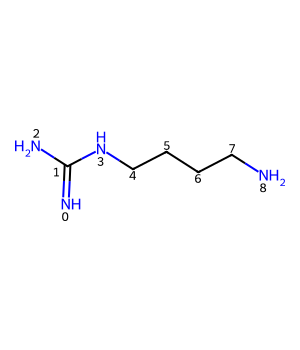

In [12]:
# smi = 'NC(CCCNCN=[NH2+])C(=O)O'
smi = 'N=C(N)NCCCCN'
mol = Chem.MolFromSmiles(smi, sanitize=True)
smi = Chem.MolToSmiles(mol)
print(smi)
from utils.chem import show_mol_svg
from rdkit import Chem
from IPython.display import SVG

SVG(show_mol_svg(smi))

In [8]:
target_molecule

'NC(=O)NCCCC[NH3+]'

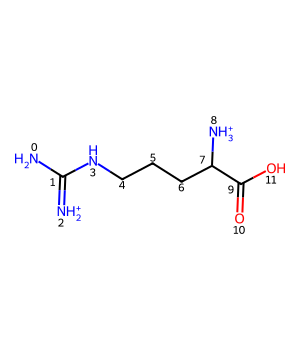

In [24]:
smi = 'NC(=[NH2+])NCCCC([NH3+])C(=O)O'
SVG(show_mol_svg(smi))

In [26]:
commercial_molecules = [
        'NC(=[NH2+])NCCC[C@H]([NH3+])C(=O)[O-]', 
        ]

from utils.chem import similarity_calculator
similarity_calculator(smi, commercial_molecules, fp_type='rdkit')

[1.0]

In [15]:
from utils.chem import similarity_calculator
similarity_calculator(target_molecule, res[0].reactants, fp_type='maccs')

[0.7419354838709677]

In [1]:
d = {}
d['aa'] = ('a', 111)
d

{'aa': ('a', 111)}

In [ ]:
target_molecule: str = '[NH3+]CCCC[NH3+]'
commercial_molecules = [
	# 'NC(=[NH2+])NCCC[C@H]([NH3+])C(=O)[O-]', 
    'NC(=[NH2+])NCCC[C@H]([NH3+])C(=O)[O-]'
	]
res = single_fn(target_molecule, commercial_molecules, ec_level=3)
res 

[SingleStepResult(reactants=['NC(=[NH2+])NCCCC([NH3+])C(=O)O'], scores=0.438, ec='4.1.1', templates='[Attaching][Group]*C(=O)[O-]:7[EC]4.1.1', confidence=0.0, reaction_type='', similarity=1.0, yield_estimate=0.34180157891542284, top_k='Top-1'),
 SingleStepResult(reactants=['NC(=[NH2+])NCCCC=O'], scores=0.135, ec='2.6.1', templates='[Delete][Bond]CN:7.8[Leaving][Group]*[NH3+]:8[Attaching][Group]*=O:7[EC]2.6.1', confidence=0.0, reaction_type='', similarity=0.692, yield_estimate=0.7079895022116128, top_k='Top-2'),
 SingleStepResult(reactants=['NC(=O)NCCCC[NH3+]'], scores=0.08, ec='3.5.3', templates='[Delete][Bond]C=N:1.2[Leaving][Group]*=[NH2+]:2[Attaching][Group]*=O:1[EC]3.5.3', confidence=0.0, reaction_type='', similarity=0.442, yield_estimate=0.6963397300285427, top_k='Top-5'),
 SingleStepResult(reactants=['[NH2+]=C(NCCCC[NH3+])NP(=O)(O)O'], scores=0.029, ec='3.9.1', templates='[Attaching][Group]*P(=O)([O-])[O-]:0[EC]3.9.1', confidence=0.0, reaction_type='', similarity=0.365, yield_est

NC(=[NH2+])NCCCC([NH3+])C(=O)O


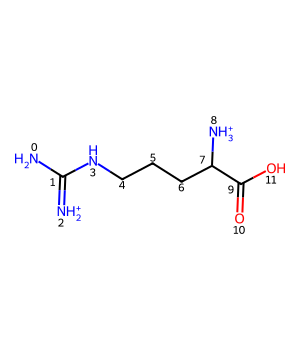

In [17]:
smi = res[0].reactants[0]
print(smi)
from utils.chem import show_mol_svg
from rdkit import Chem
from IPython.display import SVG

SVG(show_mol_svg(smi))

In [ ]:
import requests
smiles = 'CCC=CCC=CCC=CCC=CCC=CCC=CCCC(=O)O[C@H](COC(=O)CCCCCCCCCCCC=CCC=CCCCCC)COP(=O)(O)OCC[N+](C)(C)C'
# smiles = 'O=C(O)C1=C[C@@H](O)[C@@H](O)[C@H](O)C1'
url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/smiles/{smiles}/cids/TXT"
response = requests.get(url)
if response.status_code == 200 and response.text.strip()!='0':
	cid = response.text.strip()
	print(f"PubChem CID: {cid}")
	# return cid
else:
	print("没有找到匹配的CID")
	# return None

没有找到匹配的CID


In [ ]:

smi = 'O=C(O)C1=C[C@@H](O)[C@@H](O)[C@H](O)C1'

pubchem_cid = '8742'
url_kegg = f"http://rest.kegg.jp/conv/compound/pubchem:{pubchem_cid}"
response = requests.get(url_kegg)
if response.status_code == 200 and response.text.strip():
	kegg_id = response.text.strip().split("\t")[1].split(":")[1]
	print(kegg_id)


C06511


In [1]:
import pickle
from src.synthesis_tree import SynthesisTree

filename = 'results/PWY-43_biocyc_20250818_163114/synthesis_tree.pkl'
with open(filename, 'rb') as file:
	# loaded_tree = pickle.load(文件句柄)
	tree = pickle.load(file)

print(len(tree.molecule_nodes))
print(len(tree.connection_set))
tree 

164
326


In [3]:
# 步骤1: 收集所有商业分子节点
commercial_nodes = [node for node in tree.molecule_nodes.values() if node.is_commercial]
print(len(commercial_nodes))
commercial_nodes

6


[MoleculeNode(N=C(N)NCCCC(N)C(=O)O (commercial) (sim=1.000), visits=0, depth=6),
 MoleculeNode(N=C(N)NCCCC(N)C(=O)O (commercial) (sim=1.000), visits=0, depth=8),
 MoleculeNode(N=C(N)NCCCC(N)C(=O)O (commercial) (sim=1.000), visits=0, depth=4),
 MoleculeNode(N=C(N)NCCCC(N)C(=O)O (commercial) (sim=1.000), visits=0, depth=6),
 MoleculeNode(N=C(N)NCCCC(N)C(=O)O (commercial) (sim=1.000), visits=0, depth=6),
 MoleculeNode(N=C(N)NCCCC(N)C(=O)O (commercial) (sim=1.000), visits=0, depth=6)]

In [4]:
from src.nodes import ReactionNode
# 步骤2: 标记所有需要保留的节点（从商业节点回溯到根节点）
nodes_to_keep = set()
for node in commercial_nodes:
	current = node
	while current is not None:
		nodes_to_keep.add(current.id)
		# 如果是反应节点，添加其父节点
		if isinstance(current, ReactionNode) and current.parent:
			nodes_to_keep.add(current.parent.id)
		current = current.parent
print(len(nodes_to_keep))
nodes_to_keep

33


{'mol_0',
 'mol_10',
 'mol_104',
 'mol_12',
 'mol_138',
 'mol_162',
 'mol_18',
 'mol_2',
 'mol_26',
 'mol_280',
 'mol_320',
 'mol_4',
 'mol_40',
 'mol_52',
 'mol_6',
 'mol_66',
 'mol_80',
 'rxn_1',
 'rxn_103',
 'rxn_11',
 'rxn_137',
 'rxn_161',
 'rxn_17',
 'rxn_25',
 'rxn_279',
 'rxn_3',
 'rxn_319',
 'rxn_39',
 'rxn_5',
 'rxn_51',
 'rxn_65',
 'rxn_79',
 'rxn_9'}

In [6]:
len(tree.complete_paths)

2

In [7]:
tree.complete_path_counter

2

In [31]:
from src.nodes import MoleculeNode, ReactionNode
# 步骤2: 标记所有需要保留的节点（从商业节点回溯到根节点）
nodes_to_keep = set()
nodes_to_keep.add(tree.root)
for node in commercial_nodes:
    current = node
    while current is not None:
        nodes_to_keep.add(current.id)
        # 如果是反应节点，添加其父节点
        if isinstance(current, ReactionNode) and current.parent:
            nodes_to_keep.add(current.parent.id)
        current = current.parent

len(nodes_to_keep)

54

In [ ]:
# 步骤4: 删除所有未标记的节点
removed_count = 0

# 处理分子节点
for node_id, node in list(tree.molecule_nodes.items()):
    if node_id not in nodes_to_keep:
        if node.parent:
            node.parent.remove_child(node)
        del tree.molecule_nodes[node_id]
        removed_count += 1

# 处理反应节点
for node_id, node in list(tree.reaction_nodes.items()):
    if node_id not in nodes_to_keep:
        if node.parent:
            node.parent.remove_child(node)
        del tree.reaction_nodes[node_id]
        removed_count += 1

removed_count

AttributeError: 'ReactionNode' object has no attribute 'remove_child'

In [26]:
from src.nodes import MoleculeNode
def collect_commercial_paths(tree: SynthesisTree):
    """
    Collects all nodes on paths from root to commercial MoleculeNodes using post-order traversal.
    Returns a set of node IDs (using id(node)) that should be retained.
    """
    retained_nodes = set()  # IDs of nodes to keep
    stack = [(tree.root, [])]  # (node, path_nodes)
    visited = set()  # Avoid processing nodes multiple times

    while stack:
        node, path = stack.pop()
        node_id = id(node)

        if node_id in visited:
            continue
        visited.add(node_id)

        # Create a new path including the current node
        current_path = path + [node]

        # If it's a commercial MoleculeNode, retain all nodes in the path
        if isinstance(node, MoleculeNode) and node.is_commercial:
            retained_nodes.update(node.id for node in current_path)

        # Push children to stack (reverse to maintain order)
        if not node.is_leaf():
            stack.extend((child, current_path) for child in reversed(node.children))

    return retained_nodes

retained_nodes = collect_commercial_paths(tree)
print(len(retained_nodes))


53


In [28]:
removed_count = 0

# Step 2: Collect all nodes using post-order traversal
all_nodes = []
stack = [(tree.root, False)]  # (node, is_processed)
visited = set()

while stack:
    node, is_processed = stack.pop()
    node_id = node.id

    if node_id in visited:
        continue
    visited.add(node_id)

    if is_processed:
        all_nodes.append(node)
    else:
        stack.append((node, True))
        stack.extend((child, False) for child in reversed(node.children))

len(all_nodes), len(visited), len(stack)

(0, 1843, 0)

In [ ]:
# 第一步：收集所有当前叶子节点（使用栈遍历，避免递归）
leaves = []
stack = [tree.root]
visited = set()  # 避免潜在循环，虽树无环但保险
while stack:
	node = stack.pop()
	node_id = id(node)
	if node_id in visited:
		continue
	visited.add(node_id)
	if node.is_leaf():
		leaves.append(node)
	stack.extend(reversed(node.children))  # 逆序保持顺序

len(stack)

0

In [17]:
len(leaves)

735

In [ ]:
# 第二步：初始化队列，仅加入符合条件的叶子（非商业分子叶子）
from collections import deque
from src.nodes import MoleculeNode
queue = deque()
for leaf in leaves:
	if isinstance(leaf, MoleculeNode) and not leaf.is_commercial and not leaf.is_root():
		queue.append(leaf)

# for node in list(tree.molecule_nodes.values()):
# 	if node.is_leaf() and not node.is_commercial:
# 		queue.append(node)
len(queue)

728

914

In [ ]:
from collections import deque
from typing import List
import os
import json
from src.nodes import MoleculeNode, ReactionNode

# 假设SynthesisTree类已导入，且tree是SynthesisTree的实例
# 这里提供prune函数实现
def prune_dead_ends(tree):
	"""
	对树进行剪枝：从叶子节点开始，如果叶子是MoleculeNode且非商业、非根，则删除。
	删除后，如果父节点（ReactionNode或MoleculeNode）成为叶子且满足条件，则继续向上删除。
	使用迭代队列避免递归栈溢出，适合大树。
	"""
	# 第一步：收集所有当前叶子节点（使用栈遍历，避免递归）
	leaves = []
	stack = [tree.root]
	visited = set()  # 避免潜在循环，虽树无环但保险
	while stack:
		node = stack.pop()
		node_id = id(node)
		if node_id in visited:
			continue
		if node.is_root() or node.is_commercial:
			continue
		visited.add(node_id)
		# if node.is_leaf():
		leaves.append(node)
		stack.extend(reversed(node.children))  # 逆序保持顺序

	# 第二步：初始化队列，仅加入符合条件的叶子（非商业分子叶子）
	queue = deque()
	for leaf in leaves:
		if isinstance(leaf, MoleculeNode) and not leaf.is_commercial and not leaf.is_root():
			queue.append(leaf)

	# 处理过的节点集合，避免重复处理
	processed = set()

	while queue:
		node = queue.popleft()
		node_id = id(node)
		if node_id in processed:
			continue
		processed.add(node_id)

		parent = node.parent
		if not parent:
			continue  # 根节点不删除

		# 从父节点的孩子列表中移除
		if node in parent.children:
			parent.children.remove(node)

		# 从树的索引中移除节点
		if isinstance(node, MoleculeNode):
			if node.id in tree.molecule_nodes:
				del tree.molecule_nodes[node.id]
		elif isinstance(node, ReactionNode):
			if node.id in tree.reaction_nodes:
				del tree.reaction_nodes[node.id]

		# 检查父节点是否现在成为叶子
		if parent.is_leaf() and id(parent) not in processed:
			if isinstance(parent, MoleculeNode):
				# 只有非商业、非根的MoleculeNode才继续删除
				if not parent.is_commercial and not parent.is_root():
					queue.append(parent)
			elif isinstance(parent, ReactionNode):
				# ReactionNode如果为空（叶子），总是删除，因为无意义
				queue.append(parent)
	

	# 剪枝后，树的connection_set可能过时，但由于export_tree_data使用collect_tree_info重新遍历构建，不需手动更新

# 示例使用：假设tree是你的SynthesisTree实例，original_path是原始保存路径
# 先保存原始树（如果未保存）
# tree.export_tree_data(result_path="original_path")

# 复制树？但为避免内存消耗，直接在副本上操作（浅复制树结构可能不足，建议如果树大，直接prune原树并保存到新路径）
# 这里假设直接prune原树并保存到新路径
prune_dead_ends(tree)

# 保存剪枝后的树到新路径
pruned_path = "pruned_result_path"  # 指定新目录
os.makedirs(pruned_path, exist_ok=True)
print(len(tree.molecule_nodes))
print(len(tree.connection_set))
tree.export_tree_data(result_path=pruned_path)

972
1942


{'target_molecule': 'O=C[C@H](O)[C@@H](O)[C@H](O)CO',
 'commercial_molecules': ['O=CCO', 'OCCO'],
 'complete_path': [{'is_complete': True,
   'path_string': 'O=C[C@H](O)[C@@H](O)[C@H](O)CO>[Change][Bond]CO:0.1[Change][Bond]C=O:2.3[Change][Atom]C:2[EC]5.3.1>O=C(CO)C(O)C(O)CO>[Change][Bond]CO:0.1[Attaching][Group]NC(=O)c1ccc[n+]([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)OC[C@H]3O[C@@H](n4cnc5c(N)ncnc54)[C@H](O)[C@@H]3O)[C@@H](O)[C@H]2O)c1:-1[EC]1.1.1>OCC(O)C(O)C(O)CO>[Attaching][Group]*P(=O)(O)O:0[Attaching][Group]O:-1[EC]3.1.3>O=P(O)(O)OCC(O)C(O)C(O)CO>[Change][Bond]C=O:6.7[Attaching][Group][H+]:-1[Attaching][Group]NC(=O)C1=CN([C@@H]2O[C@H](COP(=O)(O)OP(=O)(O)OC[C@H]3O[C@@H](n4cnc5c(N)ncnc54)[C@H](OP(=O)(O)O)[C@@H]3O)[C@@H](O)[C@H]2O)C=CC1:-1[Change][Atom]C@:8[Change][Atom]C@@:10[EC]1.1.1>O=C(COP(=O)(O)O)[C@@H](O)[C@H](O)CO',
   'molecules': ['O=C[C@H](O)[C@@H](O)[C@H](O)CO',
    'O=C(CO)C(O)C(O)CO',
    'OCC(O)C(O)C(O)CO',
    'O=P(O)(O)OCC(O)C(O)C(O)CO',
    'O=C(COP(=O)(O)O)[C@@H](O)[C@H](O)C

In [9]:
molecule_info, reaction_info, connection_info  = tree.collect_tree_info()
print(len(molecule_info))
print(len(connection_info))

972
1942


In [ ]:
def prune_non_commercial_leaves(self):
	"""剪除非商业分子叶子节点及其无效祖先节点"""
	# 使用队列进行广度优先遍历（从叶子向根）
	queue = deque()
	
	# 初始化队列：收集所有叶子节点
	for node in self.molecule_nodes.values():
		if node.is_leaf() and not node.is_commercial:
			queue.append(node)
	
	# 记录删除的节点数
	removed_count = 0
	
	while queue:
		node = queue.popleft()
		
		# 跳过根节点和商业分子节点
		if node.is_root() or node.is_commercial:
			continue
		
		# 检查是否仍然符合删除条件
		if node.is_leaf() and not node.is_commercial:
			parent = node.parent
			
			# 安全移除当前节点
			if parent:
				parent.remove_child(node)
			if node.id in self.molecule_nodes:
				del self.molecule_nodes[node.id]
			removed_count += 1
			
			# 检查父节点是否变成叶子节点
			if parent and parent.is_leaf() and not parent.is_root():
				# 只添加分子节点（反应节点会自动处理）
				if isinstance(parent, MoleculeNode):
					queue.append(parent)
	
	# 清理连接集和路径缓存
	self.connection_set = set()
	self.all_paths = []
	self.complete_paths = []
	self.logger.info(f"剪枝完成，移除了 {removed_count} 个节点")
	return removed_count

In [2]:
tree.root

MoleculeNode(COC1=C(C=CC(=C1)C=O)O, visits=10)

In [3]:
tree.similarity_cache

{'COC1=C(C=CC(=C1)C=O)O': 0.8636363636363636,
 'O=Cc1ccc(O)c(O)c1': 0.8095238095238095,
 'O=C(O)C(=O)c1ccc(O)c(O)c1': 0.8636363636363636,
 'NC(C(=O)O)c1ccc(O)c(O)c1': 0.7037037037037037,
 'NC(C(=O)O)c1cccc(O)c1': 0.5833333333333334,
 'O=CNC(C(=O)O)c1cccc(O)c1': 0.5517241379310345,
 'N=CNC(C(=O)O)c1cccc(O)c1': 0.5,
 'N=CNC(C(=O)O)c1ccccc1': 0.3225806451612903,
 '[C-]#[N+]C(C(=O)O)c1ccccc1': 0.47619047619047616,
 '[N+]C(C(=O)O)c1ccccc1': 0.5,
 'O=C[N+]C(C(=O)O)c1ccccc1': 0.4782608695652174,
 'O=Cc1ccc(O)cc1': 0.75,
 'O=C(O)C(=O)C=Cc1ccc(O)c(O)c1': 0.8260869565217391,
 'O=Cc1cccc(O)c1': 0.75,
 'OCc1ccc(O)c(O)c1': 0.6153846153846154,
 'O=Cc1ccc(O)c(C(=O)O)c1': 0.782608695652174,
 'O=C(O)C(=O)c1ccccc1': 0.6111111111111112,
 'NC(C(=O)O)c1ccccc1': 0.375,
 'O=CNC(C(=O)O)c1ccccc1': 0.38461538461538464,
 '[N+][S+](CCC([NH3+])C(=O)O)CC1OC(n2cnc3c(N)ncnc32)C(O)C1O': 0.24324324324324326,
 'Nc1ncnc2c1ncn2C1OC(COP(=O)(O)OP(=O)(O)OCCC([NH3+])C(=O)O)C(O)C1O': 0.23376623376623376,
 'Nc1ncnc2c1ncn2C1OC(C

In [3]:
tree.molecule_nodes

{'COC1=C(C=CC(=C1)C=O)O': MoleculeNode(COC1=C(C=CC(=C1)C=O)O, visits=10),
 'O=Cc1ccc(O)c(O)c1': MoleculeNode(O=Cc1ccc(O)c(O)c1 (sim=0.810), visits=0),
 'O=Cc1ccc(O)cc1': MoleculeNode(O=Cc1ccc(O)cc1 (sim=0.750), visits=7),
 'O=C(O)C(=O)C=Cc1ccc(O)c(O)c1': MoleculeNode(O=C(O)C(=O)C=Cc1ccc(O)c(O)c1 (sim=0.826), visits=0),
 'O=Cc1cccc(O)c1': MoleculeNode(O=Cc1cccc(O)c1 (sim=0.750), visits=0),
 'O=C(O)C(=O)c1ccc(O)c(O)c1': MoleculeNode(O=C(O)C(=O)c1ccc(O)c(O)c1 (sim=0.864), visits=0),
 'OCc1ccc(O)c(O)c1': MoleculeNode(OCc1ccc(O)c(O)c1 (sim=0.615), visits=1),
 'O=Cc1ccc(O)c(C(=O)O)c1': MoleculeNode(O=Cc1ccc(O)c(C(=O)O)c1 (sim=0.783), visits=0),
 'O=C(O)C=Cc1ccc(O)cc1': MoleculeNode(O=C(O)C=Cc1ccc(O)cc1 (sim=0.882), visits=0),
 'O=C(O)Cc1ccc(O)cc1': MoleculeNode(O=C(O)Cc1ccc(O)cc1 (sim=0.700), visits=0),
 'OCc1ccc(O)cc1': MoleculeNode(OCc1ccc(O)cc1 (sim=0.524), visits=0),
 'O=C(O)C(=O)c1ccc(O)cc1': MoleculeNode(O=C(O)C(=O)c1ccc(O)cc1 (sim=0.810), visits=0),
 'O=C(O)C(=O)C=Cc1ccc(O)cc1': Molec

In [10]:
res = [m.info for m in list(tree.molecule_nodes.values())]
res

[{'node_id': 'mol_COC1=C(C=CC(=C1)C=O)O',
  'depth': 0,
  'visits': 10,
  'is_root': <bound method Node.is_root of MoleculeNode(COC1=C(C=CC(=C1)C=O)O, visits=10)>,
  'is_leaf': <bound method Node.is_leaf of MoleculeNode(COC1=C(C=CC(=C1)C=O)O, visits=10)>,
  'is_terminal': <bound method MoleculeNode.is_terminal of MoleculeNode(COC1=C(C=CC(=C1)C=O)O, visits=10)>,
  'solutions_count': 10,
  'type': 'Molecule',
  'molecule': 'COC1=C(C=CC(=C1)C=O)O',
  'is_commercial': False,
  'similarity': 0.0},
 {'node_id': 'mol_O=Cc1ccc(O)c(O)c1',
  'depth': 6,
  'visits': 0,
  'is_root': <bound method Node.is_root of MoleculeNode(O=Cc1ccc(O)c(O)c1 (sim=0.810), visits=0)>,
  'is_leaf': <bound method Node.is_leaf of MoleculeNode(O=Cc1ccc(O)c(O)c1 (sim=0.810), visits=0)>,
  'is_terminal': <bound method MoleculeNode.is_terminal of MoleculeNode(O=Cc1ccc(O)c(O)c1 (sim=0.810), visits=0)>,
  'solutions_count': 0,
  'type': 'Molecule',
  'molecule': 'O=Cc1ccc(O)c(O)c1',
  'is_commercial': False,
  'similarity':

In [13]:
tree.connection_set

{('rxn_0_1', 'mol_O=Cc1ccc(O)c(O)c1', 0.1275320053100586),
 ('rxn_10_3', 'mol_O=Cc1ccc(O)c(C(=O)O)c1', 0.04727519303560257),
 ('rxn_11_5', 'mol_O=C(O)C=Cc1ccc(O)cc1', 0.16077305376529694),
 ('rxn_12_5', 'mol_O=C(O)Cc1ccc(O)cc1', 0.1183624267578125),
 ('rxn_13_5', 'mol_OCc1ccc(O)cc1', 0.11506161093711853),
 ('rxn_14_5', 'mol_O=C(O)C(=O)c1ccc(O)cc1', 0.11269856989383698),
 ('rxn_15_5', 'mol_O=C(O)C=Cc1ccc(O)cc1', 0.09323442727327347),
 ('rxn_16_5', 'mol_O=C(O)C(=O)C=Cc1ccc(O)cc1', 0.08995276689529419),
 ('rxn_17_5', 'mol_Oc1ccc(C=Cc2cc(O)cc(O)c2)cc1', 0.08794501423835754),
 ('rxn_18_5', 'mol_O=C(O)C(=O)c1ccc(O)cc1', 0.07776899635791779),
 ('rxn_19_5', 'mol_OCc1ccc(O)cc1', 0.07343225926160812),
 ('rxn_1_3', 'mol_O=Cc1ccc(O)cc1', 0.25936388969421387),
 ('rxn_20_5', 'mol_O=C(O)Cc1ccc(O)cc1', 0.07077085226774216),
 ('rxn_21_5', 'mol_O=C(O)C=Cc1ccc(O)cc1', 0.16077305376529694),
 ('rxn_22_5', 'mol_O=C(O)Cc1ccc(O)cc1', 0.1183624267578125),
 ('rxn_23_5', 'mol_OCc1ccc(O)cc1', 0.11506161093711853)

In [11]:
res.sort(key=lambda x: x['depth'])

In [12]:
res

[{'node_id': 'mol_COC1=C(C=CC(=C1)C=O)O',
  'depth': 0,
  'visits': 10,
  'is_root': <bound method Node.is_root of MoleculeNode(COC1=C(C=CC(=C1)C=O)O, visits=10)>,
  'is_leaf': <bound method Node.is_leaf of MoleculeNode(COC1=C(C=CC(=C1)C=O)O, visits=10)>,
  'is_terminal': <bound method MoleculeNode.is_terminal of MoleculeNode(COC1=C(C=CC(=C1)C=O)O, visits=10)>,
  'solutions_count': 10,
  'type': 'Molecule',
  'molecule': 'COC1=C(C=CC(=C1)C=O)O',
  'is_commercial': False,
  'similarity': 0.0},
 {'node_id': 'mol_O=Cc1ccc(O)cc1',
  'depth': 4,
  'visits': 7,
  'is_root': <bound method Node.is_root of MoleculeNode(O=Cc1ccc(O)cc1 (sim=0.750), visits=7)>,
  'is_leaf': <bound method Node.is_leaf of MoleculeNode(O=Cc1ccc(O)cc1 (sim=0.750), visits=7)>,
  'is_terminal': <bound method MoleculeNode.is_terminal of MoleculeNode(O=Cc1ccc(O)cc1 (sim=0.750), visits=7)>,
  'solutions_count': 7,
  'type': 'Molecule',
  'molecule': 'O=Cc1ccc(O)cc1',
  'is_commercial': False,
  'similarity': 0.75},
 {'node

In [4]:
molecule_info, reaction_info, connection_info = tree.collect_tree_info()
molecule_info

In [1]:
from config.config import MCTSConfig
cfg = MCTSConfig()
cfg

MCTSConfig(project_name='Biocyc_PWY_7178_20250816_110116', target_molecule='O=C[C@H](O)[C@@H](O)[C@H](O)CO', random_seed=100, c_param=1.4, max_iterations=50, max_simulation_depth=10, early_stopping_threshold=0.01, real_time_feedback_interval=1, enable_progressive_widening=True, progressive_widening_alpha=0.5, epsilon_greedy=0.2, result_path='results/Biocyc_PWY_7178_20250816_110116', single_fn_type='biocyc', hypervolume_improvement_threshold=0.001, pareto_front_update_frequency=10, min_iterations_before_early_stop=100, max_iterations_without_improvement=200)

In [4]:
from dataclasses import dataclass, asdict, is_dataclass
res = asdict(cfg)
res

{'project_name': 'Biocyc_PWY_7178_20250816_110116',
 'target_molecule': 'O=C[C@H](O)[C@@H](O)[C@H](O)CO',
 'random_seed': 100,
 'c_param': 1.4,
 'max_iterations': 50,
 'max_simulation_depth': 10,
 'early_stopping_threshold': 0.01,
 'real_time_feedback_interval': 1,
 'enable_progressive_widening': True,
 'progressive_widening_alpha': 0.5,
 'epsilon_greedy': 0.2,
 'result_path': 'results/Biocyc_PWY_7178_20250816_110116',
 'single_fn_type': 'biocyc',
 'hypervolume_improvement_threshold': 0.001,
 'pareto_front_update_frequency': 10,
 'min_iterations_before_early_stop': 100,
 'max_iterations_without_improvement': 200}

In [5]:
res.update({"a": 99})

In [6]:
res

{'project_name': 'Biocyc_PWY_7178_20250816_110116',
 'target_molecule': 'O=C[C@H](O)[C@@H](O)[C@H](O)CO',
 'random_seed': 100,
 'c_param': 1.4,
 'max_iterations': 50,
 'max_simulation_depth': 10,
 'early_stopping_threshold': 0.01,
 'real_time_feedback_interval': 1,
 'enable_progressive_widening': True,
 'progressive_widening_alpha': 0.5,
 'epsilon_greedy': 0.2,
 'result_path': 'results/Biocyc_PWY_7178_20250816_110116',
 'single_fn_type': 'biocyc',
 'hypervolume_improvement_threshold': 0.001,
 'pareto_front_update_frequency': 10,
 'min_iterations_before_early_stop': 100,
 'max_iterations_without_improvement': 200,
 'a': 99}